# Time mean momentum flux spectra for all Concordiasi and Strateole-2 data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 0.5 # (minutes) the time step of the interpolated data
#dt = 2 # (minutes)

# Thresholds for limiting the size of spectra
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period
PERIOD_MAX = 2*24*60 # (minutes) the maximum period for spectrum output

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data

In [3]:
flights = pd.read_feather('Concordiasi_with_ERA5_5_interpolated.feather')
#flights = pd.read_feather('Strateole2_with_ERA5_4_interpolated.feather')
flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_ERA5,N2_ERA5,superpressure,segment_id
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,61.573,8.44,-9.58,192.615719,0.000580,7.54,0
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,61.616,8.36,-9.75,192.613123,0.000580,7.70,0
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,61.715,8.37,-9.82,192.607186,0.000579,7.83,0
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,61.751,8.40,-9.79,192.605042,0.000579,7.97,0
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,61.691,8.43,-9.68,192.608620,0.000579,8.11,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2382171,19,2010-11-23 09:56:00,-76.331482,-20.582638,17357.0,66.633,10.34,6.53,207.918384,0.000660,11.57,167
2382172,19,2010-11-23 09:56:30,-76.329704,-20.570866,17358.1,66.584,10.33,6.50,207.932783,0.000660,11.60,167
2382173,19,2010-11-23 09:57:00,-76.327957,-20.559189,17359.9,66.571,10.30,6.47,207.936609,0.000660,11.62,167
2382174,19,2010-11-23 09:57:30,-76.326241,-20.547585,17361.2,66.583,10.28,6.44,207.933077,0.000660,11.63,167


### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,s0,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the Concordiasi data has pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_ERA5)
    Nref = np.sqrt(np.array(segment.N2_ERA5))
    
    # Calculate segment mean environmental properties
    rho_bar = np.nanmean(pt/(R*T_env))
    T_env = np.nanmean(T_env)
    #Nref = np.nanmean(Nref)
    Nref = (0.5 + 1.5*np.random.random())*np.nanmean(Nref)
    
    # Calculate the environmental lapse rate
    dTdz_env = (T_env/g)*(Nref**2) - (g/cp) # VH14 Eq. 6
    
    # Calculate the segment mean density scale height
    H = T_env/(dTdz_env + g/R)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180)) 
    
    # Calculate Z_EDS
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_mean_spectra_output = segment_mean_spectra_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                                                               omega0,dt,dj,
                                                               Nref,rho_bar,Omega,Z_EDS,H,
                                                               PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX)
    
    return segment_mean_spectra_output

### Calculate energies, momentum fluxes

In [6]:
@dataclass
class ReturnValue2:
    frequency: float;
    N_spectra: float;
    Etotal_scaled_spectrum: float;
    flux_ReUVW_spectrum: float;
    flux_ReUpW_spectrum: float;
    flux_ImUpPT_spectrum: float;
    flux_AbsUVW_spectrum: float;
    flux_AbsUpW_spectrum: float;
    flux_AbsUpPT_spectrum: float;
    flux_ReUVW_timeseries: float;
    flux_AbsUVW_timeseries: float;
    flux_ReUpW_timeseries: float;
    flux_AbsUpW_timeseries: float;
    flux_ImUpPT_timeseries: float;
    flux_AbsUpPT_timeseries: float;
    flux_scaledEtotal_timeseries: float;
    Ep_scaled_spectrum: float;
    flux_scaledEp_timeseries: float;

def segment_mean_spectra_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                                 omega0,dt,dj,
                                 Nref,rho_bar,Omega,Z_EDS,H,
                                 PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    std_pt = np.std(pt)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    var_pt = std_pt**2
    
    # Run the wavelet analysis for u and v
    print('Wavelet analysis: u, v')
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    # Tile a couple variables
    scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
    period_tiled_padded = np.tile(period,(N + 2*N_pad,1)).swapaxes(0,1)
    
    
    
    ## CALCULATE THE U_PARALLEL WAVELET
    print('U_parallel')
    # Select only the scales relevant for GW analysis, to save memory
    ind_max_period = period[period <= PERIOD_MAX].size
    ind_min_period = 0
    nscales_GW = ind_max_period - ind_min_period
    # Extract the real and imaginary components of u and v
    Ur = np.sqrt(var_u/var_ratio)*np.real(u_output.wave[ind_min_period:ind_max_period,:])
    Ui = np.sqrt(var_u/var_ratio)*np.imag(u_output.wave[ind_min_period:ind_max_period,:])
    Vr = np.sqrt(var_v/var_ratio)*np.real(v_output.wave[ind_min_period:ind_max_period,:])
    Vi = np.sqrt(var_v/var_ratio)*np.imag(v_output.wave[ind_min_period:ind_max_period,:])
    # Temporary variables for up, ud calculation
    A = Ur**2 + Vr**2
    B = Ui**2 + Vi**2
    C = Ur*Ui + Vr*Vi
    # For uh**2 = u**2 + v**2, solve the equation for theta for when d(uh)/d(theta) = 0.
    # This will give two answers, pi/2 apart: when uh is at a minimum (Ud) and when it is
    # at a maximum (Up). Theta is the phase shift relative to the current time step.
    guess_theta = np.nan*np.ones(shape=(2,nscales_GW,N + 2*N_pad))
    guess_theta[0,:,:] = 0.5*np.arctan2(2*C,(B-A))
    guess_theta[1,:,:] = guess_theta[0,:,:] + np.pi/2
    # Plug the phase into the equation for uh:
    A = np.tile(A,(2,1,1))
    B = np.tile(B,(2,1,1))
    C = np.tile(C,(2,1,1))
    guess_Up = np.sqrt(A*(np.cos(guess_theta))**2 + 
                       B*(np.sin(guess_theta))**2 - 
                       C*np.sin(2*guess_theta))
    del A, B, C
    # From the two angles, pi/2 apart, get u_parallel (Up)
    Up = np.max(guess_Up,0)
    # If up maximizes at the guess_theta angle that corresponds to Up, the phase of up
    # at the current time step is the negative of that angle.
    temp = np.tile(Up,(2,1,1)) - guess_Up
    theta_Up = -np.nansum(guess_theta*np.isnan(temp/temp),0)
    del guess_Up, temp
    # Set Up and its angle to zero if nan
    Up[np.isnan(Up)==1] = 0
    theta_Up[np.isnan(theta_Up)==1] = 0
    # When up is at a maximum (-theta_Up), calculate the angle it makes clockwise from due East.
    Up_u = Ur*np.cos(-theta_Up) - Ui*np.sin(-theta_Up)
    Up_v = Vr*np.cos(-theta_Up) - Vi*np.sin(-theta_Up)
    theta_horiz_wave = np.arctan2(Up_v,Up_u)
    del Ur, Ui, Vr, Vi
    # There's a 180-degree ambiguity in the phases, giving the impression that up/d
    # sweep through only one-half period, with theta_horiz flipping 180 degrees
    # after each of these half-periods. Pick one side of zero for theta_horiz and shift the
    # phase of Up (theta_Up) by 180 degrees on that side.
    theta_Up[theta_horiz_wave<0] = theta_Up[theta_horiz_wave<0] - np.pi
    # Make sure theta_Up goes from -pi to pi
    theta_Up[theta_Up>np.pi] = theta_Up[theta_Up>np.pi] - 2*np.pi
    theta_Up[theta_Up<-np.pi] = theta_Up[theta_Up<-np.pi] + 2*np.pi
    del Up_u, Up_v, theta_horiz_wave
    # Calculate the real and imaginary components of up and ud.
    # For theta = 0 at the current time step, up = Up*cos(theta+theta_Up),
    # and up = UPr*cos(theta) - Upi*sin(theta), at theta = 0 or pi/2:
    Upr = Up*np.cos(theta_Up)
    Upi = Up*np.sin(theta_Up)
    del theta_Up
    # Calculate the total power of Up (the wavelet that I'm starting from is the 
    # dimensional amplitude, not the non-dimensional wavelet)
    Up_total_power = (dj*dt/C_delta)*np.sum(Up**2/scale_tiled_padded[ind_min_period:ind_max_period,:], axis=0) # (Eq. 24)
    del Up
    
    
    
    # Wavelet analysis for w, pt, delta_theta
    print('Wavelet analysis: w, delta_theta, pt')
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    pt_output = run_Morlet_CWT(pt,dt,omega0,dj)
    
    
    
    ## CALCULATE THE ENERGY WAVELETS
    print('Energy')
    # Calculate the EKE from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    # Calculate the EPE from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    # Calculate total energy
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    del wave_Ekh, wave_Ekv
    
    
    
    ## MOMENTUM FLUX FROM WAVELET CROSS-SPECTRUM
    print('Cross-spectra')
    # Using the reconstructed up:
    # Normalize the up wavelet amplitudes
    var_up_recon = (1/N)*np.nansum(Up_total_power)
    std_up_recon = np.sqrt(var_up_recon)
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    # Calculate the up-w wavelet cross-spectrum
    temp = w_output.wave[ind_min_period:ind_max_period,:]*np.conj(wave_up) # this is the normalized spectrum
    # Assuming that all GWs are propagating upward, the momentum flux must be positive
    # in the direction of Up (the wavenumber vector). If the real part of the cross-spectrum
    # is negative, flip theta_horiz, the polarization of Up and Ud, and recalculate the cross-spectrum.
    temp = np.real(temp)
    Upr[temp<0] = -Upr[temp<0]; Upi[temp<0] = -Upi[temp<0]
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    crossspec_up_w = (1+1j)*np.zeros(shape=(nscales,N+2*N_pad))
    crossspec_up_w[ind_min_period:ind_max_period,:] = w_output.wave[ind_min_period:ind_max_period,:]* \
                                                      np.conj(wave_up) # this is the normalized spectrum
    # Calculate the up-pt wavelet cross-spectrum
    temp = pt_output.wave[ind_min_period:ind_max_period,:]*np.conj(wave_up) # this is the normalized spectrum
    # Assuming that all GWs are propagating upward, the momentum flux must be positive
    # in the direction of Up (the wavenumber vector). If the imaginary part of the cross-spectrum
    # is negative, flip theta_horiz, the polarization of Up and Ud, and recalculate the cross-spectrum.
    temp = np.imag(temp)
    Upr[temp<0] = -Upr[temp<0]; Upi[temp<0] = -Upi[temp<0]
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    crossspec_up_pt = (1+1j)*np.zeros(shape=(nscales,N+2*N_pad))
    crossspec_up_pt[ind_min_period:ind_max_period,:] = pt_output.wave[ind_min_period:ind_max_period,:]* \
                                                       np.conj(wave_up) # this is the normalized spectrum
    del temp, Upr, Upi
    # Calculate the cross-spectra of u, v and the vertical velocity
    crossspec_u_w = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
    crossspec_v_w = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum
    # Calculate C_delta so that the cross-spectral power is conserved, using the full
    # u-w and v-w cross-spectra
    uw_bar = np.nanmean(u*w)
    vw_bar = np.nanmean(v*w)
    temp = (std_u*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
    C_delta_uw = (1/N)*np.sum(temp)/uw_bar
    temp = (std_v*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
    C_delta_vw = (1/N)*np.sum(temp)/vw_bar
    del temp, scale_tiled_padded
    
    
    
    ## CALCULATE TIME SERIES AND GLOBAL SPECTRA OF THE GW MOMENTUM FLUX
    print('Time series')
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    # The coefficient factor is 1 if the coefficient is in the GW frequency range, NaN if not
    balloon_lat_padded = np.nan*np.ones(N+2*N_pad)
    balloon_lat_padded[N_pad:N+N_pad] = balloon_lat
    balloon_lat_padded[:N_pad] = balloon_lat[0]
    balloon_lat_padded[N+N_pad:] = balloon_lat[-1]
    coeff_factor = 60*2*Omega*np.sin(np.pi*np.abs(balloon_lat_padded)/180) # Coriolis frequency in rad/min
    coeff_factor = 2*np.pi/coeff_factor # period in minutes
    coeff_factor = np.minimum(coeff_factor,GW_PERIOD_MAX)
    coeff_factor = np.tile(coeff_factor,(nscales,1))
    coeff_factor[coeff_factor < period_tiled_padded] = np.nan
    # Identify wavelet coefficients with periods lower than PERIOD_MIN
    period_N = 2*np.pi/(60*Nref) # the buoyancy period
    min_period = np.maximum(GW_PERIOD_MIN,period_N)
    coeff_factor[period_tiled_padded < min_period] = np.nan
    coeff_factor = coeff_factor/coeff_factor
    ## Count the number of spectra that are averaged together
    #N_spectra = N*np.ones(nscales)
    ##N_spectra = np.nansum(coeff_factor, axis=1) # if deleting wavelet coefficients when calculating global spectra

    # Rescale the wavelet cross-spectra so that the frequency-integrated fluxes are equal to the
    # integrals of the spectra times frequency over dlog(frequency), which is dj*np.log(2)
    # (log base e). The energy wavelets have already been rescaled in this way.
    # The total momentum flux from the u-w, v-w wavelet cross-spectra
    temp_rescaling = (std_w/var_ratio)*(dt)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    crossspec_ReUVW = temp_rescaling*np.sqrt(np.real(std_u*crossspec_u_w/C_delta_uw)**2 + np.real(std_v*crossspec_v_w/C_delta_uw)**2)
    cross_total_power_ReUVW = dj*np.log(2)*np.nansum(coeff_factor*crossspec_ReUVW/period_tiled_padded, axis=0)
    crossspec_AbsUVW = temp_rescaling*np.sqrt(np.abs(std_u*crossspec_u_w/C_delta_uw)**2 + np.abs(std_v*crossspec_v_w/C_delta_uw)**2)
    cross_total_power_AbsUVW = dj*np.log(2)*np.nansum(coeff_factor*crossspec_AbsUVW/period_tiled_padded, axis=0)
    del crossspec_u_w, crossspec_v_w
    # The u_parallel-w wavelet cross-spectra
    temp_rescaling = (std_up_recon*std_w/var_ratio)*(dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    crossspec_up_w = crossspec_up_w*temp_rescaling
    cross_total_power_ReUpW = dj*np.log(2)*np.nansum(coeff_factor*np.real(crossspec_up_w)/period_tiled_padded, axis=0)
    cross_total_power_AbsUpW = dj*np.log(2)*np.nansum(coeff_factor*np.abs(crossspec_up_w)/period_tiled_padded, axis=0)
    #del crossspec_up_w
    # The u_parallel-pressure wavelet cross-spectra
    temp_rescaling = (std_up_recon*std_pt/var_ratio)*(dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    factor = np.tile(frequency,(N+2*N_pad,1)).swapaxes(0,1)
    factor = (2*np.pi*factor/60)/(rho_bar*H*Nref**2) # VH14 Eq. 26
    crossspec_up_pt = crossspec_up_pt*temp_rescaling*factor
    del factor
    cross_total_power_ImUpPT = dj*np.log(2)*np.nansum(coeff_factor*np.imag(crossspec_up_pt)/period_tiled_padded, axis=0)
    cross_total_power_AbsUpPT = dj*np.log(2)*np.nansum(coeff_factor*np.abs(crossspec_up_pt)/period_tiled_padded, axis=0)
    #del crossspec_up_pt
    # Total momentum fluxes from re-scaled Etotal
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat_padded/180),(nscales,1))
    frequency_rad = 2*np.pi*frequency/60
    frequency_rad = np.tile(frequency_rad,(N+2*N_pad,1)).swapaxes(0,1)
    factor = (frequency_rad**2 - f_temp**2)/(Nref**2 - f_temp**2)
    factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f_temp**2)
    factor = np.sqrt(factor)
    wave_Etotal = wave_Etotal*factor
    # from re-scaled Ep
    factor = (Nref**2 - frequency_rad**2)/(frequency_rad**2 - f_temp**2)
    factor = 2*np.sqrt(factor)*(frequency_rad**2)/(Nref**2)
    wave_Ep = wave_Ep*factor
    del factor
    flux_total_Etotal = dj*np.log(2)*np.nansum(coeff_factor*wave_Etotal/period_tiled_padded, axis=0)
    flux_total_Ep = dj*np.log(2)*np.nansum(coeff_factor*wave_Ep/period_tiled_padded, axis=0)
    del f_temp, frequency_rad
    del coeff_factor, period_tiled_padded
    
    # Delete coefficients that are inside the cone of influence or have frequencies lower than f 
    # and calculate time-mean spectra
    # Remove zero padding
    print('Global spectra')
    crossspec_up_w = crossspec_up_w[:,N_pad:N+N_pad]
    crossspec_up_pt = crossspec_up_pt[:,N_pad:N+N_pad]
    crossspec_ReUVW = crossspec_ReUVW[:,N_pad:N+N_pad]
    crossspec_AbsUVW = crossspec_AbsUVW[:,N_pad:N+N_pad]
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    wave_Ep = wave_Ep[:,N_pad:N+N_pad]
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete the offending wavelet coefficients and take the time mean
    global_ReUVW = np.nanmean(crossspec_ReUVW*temp1,axis=1)
    global_AbsUVW = np.nanmean(crossspec_AbsUVW*temp1,axis=1)
    global_ReUpW = np.nanmean(np.real(crossspec_up_w)*temp1,axis=1)
    global_AbsUpW = np.nanmean(np.abs(crossspec_up_w)*temp1,axis=1)
    global_ImUpPT = np.nanmean(np.imag(crossspec_up_pt)*temp1,axis=1)
    global_AbsUpPT = np.nanmean(np.abs(crossspec_up_pt)*temp1,axis=1)
    global_Etotal_scaled = np.nanmean(wave_Etotal*temp1,axis=1)
    global_Ep_scaled = np.nanmean(wave_Ep*temp1,axis=1)
    N_spectra = np.nansum(temp1,axis=1)
    del temp1
    
    
    
    ## ORGANIZE THE OUTPUT
    print('Output')
    # Remove the zero padding from the timeseries
    flux_ReUVW_timeseries = 1000*rho_bar*cross_total_power_ReUVW[N_pad:N+N_pad]
    flux_AbsUVW_timeseries = 1000*rho_bar*cross_total_power_AbsUVW[N_pad:N+N_pad]
    flux_ReUpW_timeseries = 1000*rho_bar*cross_total_power_ReUpW[N_pad:N+N_pad]
    flux_AbsUpW_timeseries = 1000*rho_bar*cross_total_power_AbsUpW[N_pad:N+N_pad]
    flux_ImUpPT_timeseries = 1000*rho_bar*cross_total_power_ImUpPT[N_pad:N+N_pad]
    flux_AbsUpPT_timeseries = 1000*rho_bar*cross_total_power_AbsUpPT[N_pad:N+N_pad]
    flux_scaledEtotal_timeseries = 1000*rho_bar*flux_total_Etotal[N_pad:N+N_pad]
    flux_scaledEp_timeseries = 1000*rho_bar*flux_total_Ep[N_pad:N+N_pad]
    # Identify the periods less than or equal to PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= PERIOD_MAX]
    nscales_new = nscales_new.size
    frequency = frequency[:nscales_new]
    N_spectra = N_spectra[:nscales_new]
    Etotal_scaled_spectrum = global_Etotal_scaled[:nscales_new]
    flux_ReUVW_spectrum = global_ReUVW[:nscales_new]
    flux_ReUpW_spectrum = global_ReUpW[:nscales_new]
    flux_ImUpPT_spectrum = global_ImUpPT[:nscales_new]
    flux_AbsUVW_spectrum = global_AbsUVW[:nscales_new]
    flux_AbsUpW_spectrum = global_AbsUpW[:nscales_new]
    flux_AbsUpPT_spectrum = global_AbsUpPT[:nscales_new]
    Ep_scaled_spectrum = global_Ep_scaled[:nscales_new]
    return ReturnValue2(frequency,
                        N_spectra,
                        Etotal_scaled_spectrum,
                        flux_ReUVW_spectrum,
                        flux_ReUpW_spectrum,
                        flux_ImUpPT_spectrum,
                        flux_AbsUVW_spectrum,
                        flux_AbsUpW_spectrum,
                        flux_AbsUpPT_spectrum,
                        flux_ReUVW_timeseries,
                        flux_AbsUVW_timeseries,
                        flux_ReUpW_timeseries,
                        flux_AbsUpW_timeseries,
                        flux_ImUpPT_timeseries,
                        flux_AbsUpPT_timeseries,
                        flux_scaledEtotal_timeseries,
                        Ep_scaled_spectrum,
                        flux_scaledEp_timeseries)

In [7]:
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()

# Calculate scales to size the arrays
N_temp = int(100*PERIOD_MAX/dt) # make a very large fake N to make sure I'm doing this right
s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
J = (1/dj)*np.log2(N_temp*dt/s0) # (Eq. 10)
J = int(np.ceil(J))
s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
period = period[period <= PERIOD_MAX]
nscales = period.size

# Make the spectrum fields
frequency = np.nan*np.zeros(nscales)
N_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
Etotal_scaled_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_ReUVW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_ReUpW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_ImUpPT_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_AbsUVW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_AbsUpW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_AbsUpPT_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
Ep_scaled_spectra = np.nan*np.zeros(shape=(nscales,n_segments))

# Make the dataframe that will hold the fluxes
flights['flux_Etotal_scaled'] = np.nan
flights['flux_ReUVW'] = np.nan
flights['flux_AbsUVW'] = np.nan
flights['flux_ReUpW'] = np.nan
flights['flux_AbsUpW'] = np.nan
flights['flux_ImUpPT'] = np.nan
flights['flux_AbsUpPT'] = np.nan
flights['flux_Ep_scaled'] = np.nan

for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,s0,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX)
    frequency = temp.frequency
    N_spectra[:,i] = temp.N_spectra
    Etotal_scaled_spectra[:,i] = temp.Etotal_scaled_spectrum
    flux_ReUVW_spectra[:,i] = temp.flux_ReUVW_spectrum
    flux_ReUpW_spectra[:,i] = temp.flux_ReUpW_spectrum
    flux_ImUpPT_spectra[:,i] = temp.flux_ImUpPT_spectrum
    flux_AbsUVW_spectra[:,i] = temp.flux_AbsUVW_spectrum
    flux_AbsUpW_spectra[:,i] = temp.flux_AbsUpW_spectrum
    flux_AbsUpPT_spectra[:,i] = temp.flux_AbsUpPT_spectrum
    Ep_scaled_spectra[:,i] = temp.Ep_scaled_spectrum
    flights.loc[flights.segment_id == segment_ids[i], 'flux_Etotal_scaled'] = np.array(temp.flux_scaledEtotal_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_ReUVW'] = np.array(temp.flux_ReUVW_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_AbsUVW'] = np.array(temp.flux_AbsUVW_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_ReUpW'] = np.array(temp.flux_ReUpW_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_AbsUpW'] = np.array(temp.flux_AbsUpW_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_ImUpPT'] = np.array(temp.flux_ImUpPT_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_AbsUpPT'] = np.array(temp.flux_AbsUpPT_timeseries)
    flights.loc[flights.segment_id == segment_ids[i], 'flux_Ep_scaled'] = np.array(temp.flux_scaledEp_timeseries)
    print('')

data = [frequency,
        N_spectra,
        Etotal_scaled_spectra,
        flux_ReUVW_spectra,
        flux_ReUpW_spectra,
        flux_ImUpPT_spectra,
        flux_AbsUVW_spectra,
        flux_AbsUpW_spectra,
        flux_AbsUpPT_spectra,
        Ep_scaled_spectra]
#np.savez('Concordiasi_flux_spectra_omega0_8_Ep.npz', *data) 
#segments_analyzed.to_feather('Concordiasi_momentum_fluxes_omega0_8_Ep.feather') 
#np.savez('Strateole2_flux_spectra_omega0_8_Ep.npz', *data) 
#segments_analyzed.to_feather('Strateole2_momentum_fluxes_omega0_8_Ep.feather') 

Analyzing segment 1 out of 108 segments
Segment length: 14 days 22:39:30
Current time: 2026-05-05 14:35:00.842728
Wavelet analysis: u, v
U_parallel
Wavelet analysis: w, delta_theta, pt
Energy
Cross-spectra
Time series
Global spectra
Output

Analyzing segment 2 out of 108 segments
Segment length: 2 days 03:24:00
Current time: 2026-05-05 14:35:25.721665
Wavelet analysis: u, v
U_parallel
Wavelet analysis: w, delta_theta, pt
Energy
Cross-spectra
Time series
Global spectra
Output

Analyzing segment 3 out of 108 segments
Segment length: 3 days 17:57:00
Current time: 2026-05-05 14:35:28.121232
Wavelet analysis: u, v
U_parallel
Wavelet analysis: w, delta_theta, pt
Energy
Cross-spectra
Time series
Global spectra
Output

Analyzing segment 4 out of 108 segments
Segment length: 2 days 03:57:30
Current time: 2026-05-05 14:35:32.689225
Wavelet analysis: u, v
U_parallel
Wavelet analysis: w, delta_theta, pt
Energy
Cross-spectra
Time series
Global spectra
Output

Analyzing segment 5 out of 108 segments

### Load in the analyzed data

In [7]:
container = np.load('Concordiasi_flux_spectra_omega0_8_Ep.npz')
#container = np.load('Strateole2_flux_spectra_omega0_8_Ep.npz')
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98
data = [container[key] for key in container]
frequency = data[0]
N_spectra = data[1]
Etotal_scaled_spectra = data[2]
flux_UVW_spectra = data[3]
flux_UpW_spectra = data[4]
flux_UpPT_spectra = data[5]
flux_AbsUVW_spectra = data[6]
flux_AbsUpW_spectra = data[7]
flux_AbsUpPT_spectra = data[8]
Ep_scaled_spectra = data[9]

# Average across the segments
Etotal_scaled_mean_spectrum = np.nansum(Etotal_scaled_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_UVW_mean_spectrum = np.nansum(flux_UVW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_UpW_mean_spectrum = np.nansum(flux_UpW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_UpPT_mean_spectrum = np.nansum(flux_UpPT_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_AbsUVW_mean_spectrum = np.nansum(flux_AbsUVW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_AbsUpW_mean_spectrum = np.nansum(flux_AbsUpW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_AbsUpPT_mean_spectrum = np.nansum(flux_AbsUpPT_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
Ep_scaled_mean_spectrum = np.nansum(Ep_scaled_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)

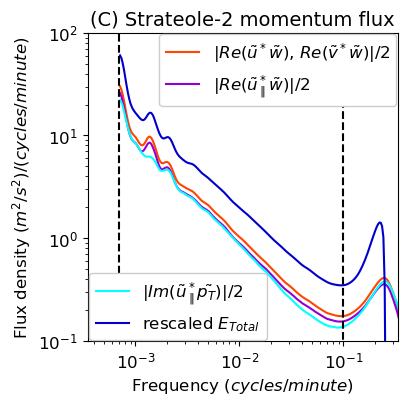

In [6]:
# Fig. 2C

fig, ax = plt.subplots(figsize=(4,4))
ymin = 1E-1
ymax = 1E2
line1, = ax.plot(frequency, flux_UVW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line2, = ax.plot(frequency, flux_UpW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line3, = ax.plot(frequency, flux_UpPT_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'|$Im(\tilde{u}_\parallel^*\tilde{p_T})$|/2')
line4, = ax.plot(frequency, Etotal_scaled_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line5, = ax.plot([1/10, 1/10], [0, ymax],'--k',
                 label = r'1/(10 min., 1 day)')
ax.plot([1/1440, 1/1440], [0, ymax],'--k')
ax.set_xlim(1/(2*24*60),1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('(C) Strateole-2 momentum flux', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2], 
                         loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line3, line4],
          loc='lower left', bbox_to_anchor=(-0.023, -0.024), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp5a.pdf', format='pdf', bbox_inches='tight');

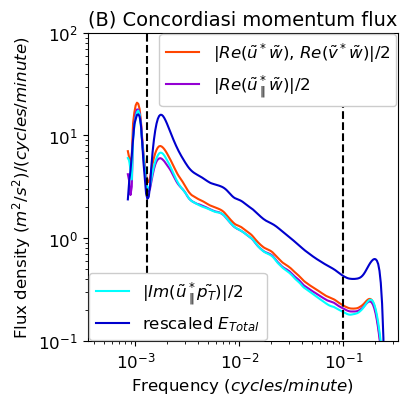

In [8]:
# Fig. 2B

temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

fig, ax = plt.subplots(figsize=(4,4))
ymin = 1E-1
ymax = 1E2
line1, = ax.plot(frequency, flux_UVW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line2, = ax.plot(frequency, flux_UpW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line3, = ax.plot(frequency, flux_UpPT_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'|$Im(\tilde{u}_\parallel^*\tilde{p_T})$|/2')
line4, = ax.plot(frequency, Etotal_scaled_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line5, = ax.plot([1/10, 1/10], [0, ymax],'--k',
                 label = r'1/(10 min.), $f$ at 70$^\circ$')
ax.plot([temp_f, temp_f], [0, ymax],'--k')
ax.set_xlim(1/(2*24*60),1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('(B) Concordiasi momentum flux', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2], 
                         loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line3, line4],
          loc='lower left', bbox_to_anchor=(-0.023, -0.024), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp4a.pdf', format='pdf', bbox_inches='tight');

In [4]:
#flights = pd.read_feather('Concordiasi_momentum_fluxes_omega0_8_Ep.feather')
flights = pd.read_feather('Strateole2_momentum_fluxes_omega0_8_Ep.feather')

# Chop off the first and last two hours of each segment
def dt_start_end(segment):
    
    segment['dt_start'] = (segment.time - segment.time.iloc[0])/pd.Timedelta(1,'hours')
    segment['dt_end'] = (segment.time.iloc[-1] - segment.time)/pd.Timedelta(1,'hours')
    
    return segment

flights = flights.groupby('segment_id').progress_apply(dt_start_end)
flights = flights[flights.dt_start > 2]
flights = flights[flights.dt_end > 2]

  0%|          | 0/57 [00:00<?, ?it/s]

In [5]:
# Values in Table 1

print('Mean total momentum flux (mPa)')

temp = np.array(flights.flux_Etotal_scaled)
temp[temp == 0] = np.nan
print('from scaled Etotal:', np.nanmean(temp))

temp = np.array(flights.flux_Ep_scaled)
temp[temp == 0] = np.nan
print('from scaled Ep:', np.nanmean(temp))

temp = np.array(flights.flux_ReUVW)
temp[temp == 0] = np.nan
print('from Re(uw,vw):', np.nanmean(temp))

temp = np.array(flights.flux_AbsUVW)
temp[temp == 0] = np.nan
print('from Abs(uw,vw):', np.nanmean(temp))

temp = np.array(flights.flux_ReUpW)
temp[temp == 0] = np.nan
print('from Re(upw):', np.nanmean(temp))

temp = np.array(flights.flux_AbsUpW)
temp[temp == 0] = np.nan
print('from Abs(upw):', np.nanmean(temp))

temp = np.array(flights.flux_ImUpPT)
temp[temp == 0] = np.nan
print('from Im(uppt):', np.nanmean(temp))

temp = np.array(flights.flux_AbsUpPT)
temp[temp == 0] = np.nan
print('from Abs(uppt):', np.nanmean(temp))

print()
temp1 = np.array(flights.flux_ReUpW)
temp1[temp1 == 0] = np.nan
temp2 = np.array(flights.flux_AbsUpW)
temp2[temp2 == 0] = np.nan
temp = np.nanmean(temp1)/np.nanmean(temp2)
print('Ratio of Re(upw) to Abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp3 = np.array(flights.flux_Etotal_scaled)
temp3[temp3 == 0] = np.nan
temp1a = np.nanmean(temp2) - np.nanmean(temp1)
temp2a = np.nanmean(temp3) - np.nanmean(temp1)
print('Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw):', 100*(temp1a/temp2a))

print()
temp1 = np.array(flights.flux_ImUpPT)
temp1[temp1 == 0] = np.nan
temp2 = np.array(flights.flux_AbsUpPT)
temp2[temp2 == 0] = np.nan
temp = np.nanmean(temp1)/np.nanmean(temp2)
print('Ratio of Im(uppt) to Abs(uppt):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp3 = np.array(flights.flux_Etotal_scaled)
temp3[temp3 == 0] = np.nan
temp1a = np.nanmean(temp2) - np.nanmean(temp1)
temp2a = np.nanmean(temp3) - np.nanmean(temp1)
print('Percent of (scaled energy) - im(uppt) explained by abs(uppt) - im(uppt):', 100*(temp1a/temp2a))

Mean total momentum flux (mPa)
from scaled Etotal: 11.20103623740209
from scaled Ep: 12.03114365750092
from Re(uw,vw): 5.838976304252588
from Abs(uw,vw): 9.141543260564877
from Re(upw): 5.066679879813696
from Abs(upw): 8.383897031734975
from Im(uppt): 4.704571755690417
from Abs(uppt): 7.893923951397136

Ratio of Re(upw) to Abs(upw): 0.6043346978899132
Effective phase error (degrees): 52.819017576469165
Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw): 54.07604251451378

Ratio of Im(uppt) to Abs(uppt): 0.5959737875176465
Effective phase error (degrees): 53.417917623052446
Percent of (scaled energy) - im(uppt) explained by abs(uppt) - im(uppt): 49.093660169852825
